## __Feed Forward Model — Dual-Branch Survival Network__

Trains a dual-branch neural network (clinical + expression) to predict 5-year survival, using both the PCA-reduced and DESeq2-selected expression feature sets.

### Imports

In [ ]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

import pandas as pd
import numpy as np
import os
import torch
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve, recall_score, PrecisionRecallDisplay
import matplotlib.pyplot as plt
from src.ML_model import DualBranchSurvival, Survival_Model
from dotenv import load_dotenv

load_dotenv("project.env")

c:\Users\ernes\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

### Creation of the datasets

### PCA dataset

In [2]:
X_expression = pd.read_csv(os.path.join(os.getenv("Output_path"),'Countdata.csv')).set_index('file_id')
X_expression = np.log1p(X_expression)
X_clinical = pd.read_csv(os.path.join(os.getenv("Output_path"),'metadata.csv')).set_index('file_id')
X_clinical = X_clinical.loc[X_clinical.index.intersection(X_expression.index)]  # restrict to tumor-only cohort
y = X_clinical.loc[:, X_clinical.columns == 'survival_5yrs']
y = y.loc[X_expression.index]
X_clinical_ = X_clinical.loc[:, X_clinical.columns != 'survival_5yrs']

In [3]:
X_clinical_['race'] = LabelEncoder().fit_transform(X_clinical_['race']) 
X_clinical_['gender'] = LabelEncoder().fit_transform(X_clinical_['gender'])
X_clinical_ = X_clinical_.loc[X_expression.index]

C:\Users\ernes\AppData\Local\Temp\ipykernel_79404\1929629141.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_clinical_['race'] = LabelEncoder().fit_transform(X_clinical_['race'])
C:\Users\ernes\AppData\Local\Temp\ipykernel_79404\1929629141.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_clinical_['gender'] = LabelEncoder().fit_transform(X_clinical_['gender'])


### DESeq2 dataset

In [4]:
res_sig = pd.read_csv(os.path.join(os.getenv("Output_path"),'res_sig_list.txt'), header=None)
res_sig_list = res_sig[0].to_list()

In [5]:
D2_expression = X_expression[res_sig_list]

### Train, test, split — PCA dataset

In [6]:
X_expression_train, X_expression_test, X_clinical_train, X_clinical_test, y_train, y_test = train_test_split(
    X_expression, X_clinical_, y, test_size=0.2, stratify=y, random_state=42
) ## splitting the different datasets for training and testing 
print(f"Length splitted train dataset: {len(X_expression_train)}")
print(f"Length splitted test dataset: {len(X_expression_test)}")
print(f"Length target dataset: {len(y)}")

Length splitted train dataset: 260
Length splitted test dataset: 65
Length target dataset: 325


In [7]:
scaler = StandardScaler()

## The fit-transform preprocessing is used to compute the mean and standard deviation from the data (fit) and apply it on the subset dataset (transform)
## The full preprocessing process (with fit) cannot be applied to the test dataset, as it would induce bias, thus we are only using transform  
X_expression_train_sc = scaler.fit_transform(X_expression_train)
X_expression_test_sc = scaler.transform(X_expression_test)

y_test_raw = y_test.reset_index().copy()

pca = PCA(n_components=50) ## Save 95% of the dimensionality within the variables of the expression dataset
X_expression_train_fin = pca.fit_transform(X_expression_train_sc)
X_expression_test_fin = pca.transform(X_expression_test_sc)

### Export split datasets

Saved for reuse by the baseline models (Random Forest / Logistic Regression) in `7-baseline_model.ipynb`, so every model is tested on identical patients sets.

In [ ]:
X_expression_train.to_csv(os.path.join(os.getenv("Output_path"), "X_expression_raw_train.csv"))
X_expression_test.to_csv(os.path.join(os.getenv("Output_path"), "X_expression_raw_test.csv"))
X_clinical_train.to_csv(os.path.join(os.getenv("Output_path"), "X_clinical_train.csv"))
X_clinical_test.to_csv(os.path.join(os.getenv("Output_path"), "X_clinical_test.csv"))
y_train.to_csv(os.path.join(os.getenv("Output_path"), "y_train.csv"))
y_test.to_csv(os.path.join(os.getenv("Output_path"), "y_test.csv"))

### Convert to tensors

In [9]:
X_expression_train_fin = torch.tensor(X_expression_train_fin, dtype=torch.float32)
X_expression_test_fin = torch.tensor(X_expression_test_fin, dtype=torch.float32)

X_clinical_train = torch.tensor(X_clinical_train.to_numpy(), dtype=torch.float32)
X_clinical_test = torch.tensor(X_clinical_test.to_numpy(), dtype=torch.float32)
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

### Train, test, split — Deseq2 dataset

In [10]:
X_expression_trainD2, X_expression_testD2 = train_test_split(
    D2_expression, test_size=0.2, stratify=y, random_state=42
)
print(f"Length splitted train dataset: {len(X_expression_trainD2)}")
print(f"Length splitted test dataset: {len(X_expression_testD2)}")
print(f"Length target dataset: {len(y)}")

Length splitted train dataset: 260
Length splitted test dataset: 65
Length target dataset: 325


In [ ]:
X_expression_trainD2.to_csv(path_or_buf=os.path.join(os.getenv("Output_path"), "X_expression_D2_train.csv"))
X_expression_testD2.to_csv(path_or_buf=os.path.join(os.getenv("Output_path"), "X_expression_D2_test.csv"))

In [12]:
scaler = StandardScaler()

X_expression_train_scD2 = scaler.fit_transform(X_expression_trainD2)
X_expression_test_scD2 = scaler.transform(X_expression_testD2)
X_expression_train_scD2 = torch.tensor(X_expression_train_scD2, dtype=torch.float32)
X_expression_test_scD2 = torch.tensor(X_expression_test_scD2, dtype=torch.float32)

### __Model architecture__

`ClinicalBranch`, `ExpressionBranch`, `DualBranchSurvival`, and the `Survival_Model` training loop are defined in `src/ML_model.py`.

### __Hyperparameters__

### Loss function

In [13]:
n_pos = (y_train == 1).sum()
n_neg = (y_train == 0).sum()
print(f'n pos: {n_pos}')
print(f'n neg: {n_neg}')
weights = torch.tensor(n_neg / n_pos, dtype=torch.float32)

n pos: 187
n neg: 73


C:\Users\ernes\AppData\Local\Temp\ipykernel_79404\2442685898.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights = torch.tensor(n_neg / n_pos, dtype=torch.float32)


Testing Oversampling used to reduce skewness from the model toward the dominating class

In [14]:
n_epochs = 400
max_epochs = 150
batch_size = 100
loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor([weights])) ## Using BCEWithLogitsLoss for binary classification
patience = 10

### __Results — single train/test split__

### PCA model

Running the model:

In [15]:
Survival_Model(
    Clinical_train_df=X_clinical_train, 
    Expression_train_df=X_expression_train_fin, 
    Clinical_test_df=X_clinical_test, 
    Expression_test_df=X_expression_test_fin,
    y_train=y_train,
    y_test=y_test,
    Sel_process="PCA", 
    loss_fn=loss_fn, 
    n_epochs=n_epochs, 
    max_epochs=max_epochs, 
    batch_size=batch_size, 
    patience=patience
    )

best model reached, early stopping
best model reached, early stopping
best model reached, early stopping
best model reached, early stopping
best model reached, early stopping
best model - run: 3
best model - epoch: 31
best model - test accuracy: 0.7692307829856873
best model - test loss: 0.2638700604438782


Loading the best model and define probability and the prediction (binary)

In [18]:
best_model = torch.load(os.path.join(os.getenv("Best_models_path"), 'PCA_best_model.pt'))

n_feature_cli = best_model['n_feature_cli']
n_feature_exp = best_model['n_feature_exp']

model = DualBranchSurvival(n_feature_cli=n_feature_cli, n_feature_exp=n_feature_exp)
model.load_state_dict(best_model['model_state_dict'])
model.eval()

with torch.no_grad():
    y_pred = model(X_clinical_test,X_expression_test_fin)
    probs = torch.sigmoid(y_pred).squeeze()
    preds = (probs >=0.5).int()

In [ ]:
# class report and confusion matrix are both in independent files
# classification report 
print(classification_report(y_test.numpy(), preds.numpy()))
pd.DataFrame(classification_report(y_test.numpy(), preds.numpy(), output_dict= True)).to_excel(os.path.join(os.getenv("Output_path"), 'classification_report_PCA.xlsx'), sheet_name= 'sheet1', header = True)
# confusion matrix
print(confusion_matrix(y_test.numpy(), preds.numpy()))
pd.DataFrame(confusion_matrix(y_test.numpy(), preds.numpy())).to_excel(os.path.join(os.getenv("Output_path"), 'confusion_matrix_PCA.xlsx'), sheet_name= 'sheet1', header = True)
print(f"Roc Auc Score: {roc_auc_score(y_test, probs)}")

              precision    recall  f1-score   support

         0.0       0.55      0.89      0.68        18
         1.0       0.94      0.72      0.82        47

    accuracy                           0.77        65
   macro avg       0.75      0.81      0.75        65
weighted avg       0.84      0.77      0.78        65

[[16  2]
 [13 34]]
Roc Auc Score: 0.8546099290780143


AUC_score: 0.8546


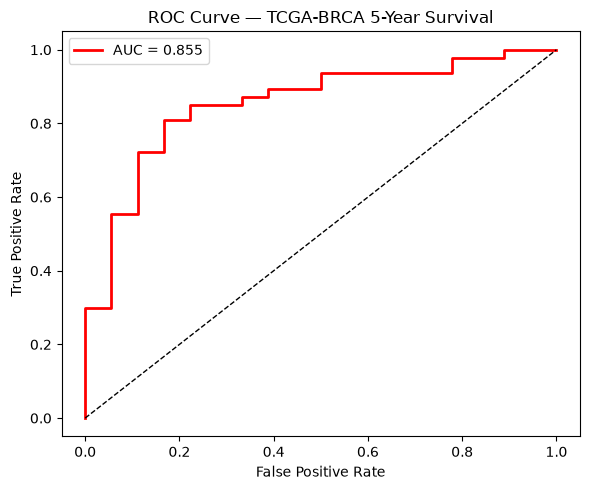

In [ ]:
auc = roc_auc_score(y_test, probs)
print(f'AUC_score: {auc:.4f}')

fpr, tpr, threshold = roc_curve(y_test, probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color = 'red', lw = 2, label = f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--', lw = 1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — TCGA-BRCA 5-Year Survival')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(os.getenv("Output_path"),'roc_curve_PCA.png'), dpi=150)
plt.show()

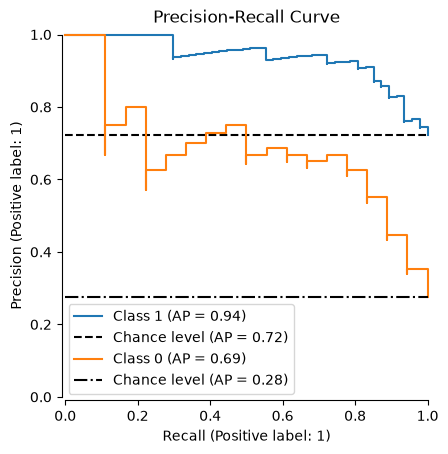

In [ ]:
fig, ax = plt.subplots()
PrecisionRecallDisplay.from_predictions(y_test, probs, name='Class 1', plot_chance_level = True, despine = True, ax = ax)
PrecisionRecallDisplay.from_predictions(1-y_test, 1-probs, name='Class 0', plot_chance_level = True, despine = True, ax = ax, chance_level_kw= {'linestyle':'-.'})
plt.title('Precision-Recall Curve')
plt.tight_layout()
plt.savefig(os.path.join(os.getenv("Output_path"),'PR_AUC_PCA.png'), dpi=150)
plt.show()

### Deseq2 model

Running the model:

In [25]:
Survival_Model(
    Clinical_train_df=X_clinical_train, 
    Expression_train_df=X_expression_train_scD2, 
    Clinical_test_df=X_clinical_test, 
    Expression_test_df=X_expression_test_scD2,
    y_train=y_train,
    y_test=y_test,
    Sel_process="Deseq2", 
    loss_fn=loss_fn, 
    n_epochs=n_epochs, 
    max_epochs=max_epochs, 
    batch_size=batch_size, 
    patience=patience
    )

best model reached, early stopping
best model reached, early stopping
best model reached, early stopping
best model reached, early stopping
best model reached, early stopping
best model - run: 0
best model - epoch: 15
best model - test accuracy: 0.692307710647583
best model - test loss: 0.309352844953537


Loading the best model and define probability and the prediction (binary)

In [27]:
best_model = torch.load(os.path.join(os.getenv("Best_models_path"), 'Deseq2_best_model.pt'))

n_feature_cli = best_model['n_feature_cli']
n_feature_exp = best_model['n_feature_exp']

model = DualBranchSurvival(n_feature_cli=n_feature_cli, n_feature_exp=n_feature_exp)
model.load_state_dict(best_model['model_state_dict'])
model.eval()

with torch.no_grad():
    y_pred = model(X_clinical_test, X_expression_test_scD2)
    probs = torch.sigmoid(y_pred).squeeze()
    preds = (probs >=0.5).int()

In [ ]:
# class report and confusion matrix are both in independent files
# classification report 
print(classification_report(y_test.numpy(), preds.numpy()))
pd.DataFrame(classification_report(y_test.numpy(), preds.numpy(), output_dict= True)).to_excel(os.path.join(os.getenv("Output_path"), 'classification_report_Deseq2.xlsx'), sheet_name= 'sheet1', header = True)
# confusion matrix
print(confusion_matrix(y_test.numpy(), preds.numpy()))
pd.DataFrame(confusion_matrix(y_test.numpy(), preds.numpy())).to_excel(os.path.join(os.getenv("Output_path"), 'confusion_matrix_Deseq2.xlsx'), sheet_name= 'sheet1', header = True)
print(f"Roc Auc Score: {roc_auc_score(y_test, probs)}")

              precision    recall  f1-score   support

         0.0       0.46      0.72      0.57        18
         1.0       0.86      0.68      0.76        47

    accuracy                           0.69        65
   macro avg       0.66      0.70      0.66        65
weighted avg       0.75      0.69      0.71        65

[[13  5]
 [15 32]]
Roc Auc Score: 0.7647754137115839


AUC_score: 0.7648


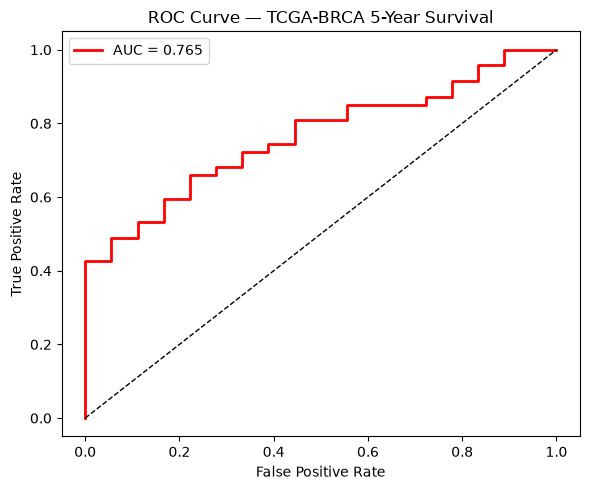

In [ ]:
auc = roc_auc_score(y_test, probs)
print(f'AUC_score: {auc:.4f}')

fpr, tpr, threshold = roc_curve(y_test, probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color = 'red', lw = 2, label = f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--', lw = 1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — TCGA-BRCA 5-Year Survival')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(os.getenv("Output_path"), 'roc_curve_Deseq2.png'), dpi=150)
plt.show()

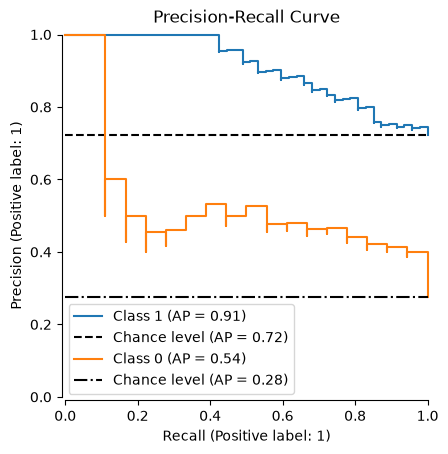

In [ ]:
fig, ax = plt.subplots()
PrecisionRecallDisplay.from_predictions(y_test, probs, name='Class 1', plot_chance_level = True, despine = True, ax = ax)
PrecisionRecallDisplay.from_predictions(1-y_test, 1-probs, name='Class 0', plot_chance_level = True, despine = True, ax = ax, chance_level_kw= {'linestyle':'-.'})
plt.title('Precision-Recall Curve')
plt.tight_layout()
plt.savefig(os.path.join(os.getenv("Output_path"),'PR_AUC_Deseq2.png'), dpi=150)
plt.show()

### __Cross-validation — Stratified K-Fold__

### PCA

In [ ]:
results_per_fold = []

splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for i, (train_idx, test_idx) in enumerate(splitter.split(X_expression, y)):

    print(f"Fold {i}")
    print("-----------------------------------------------")
    # Definition of our datasets for this fold specifically 
    X_expression_train_fold = X_expression.iloc[train_idx]
    X_expression_test_fold = X_expression.iloc[test_idx]
    X_clinical_train_fold = X_clinical_.iloc[train_idx]
    X_clinical_test_fold = X_clinical_.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]

    # Scaling
    scaler_fold = StandardScaler()
    X_exp_train_sc = scaler_fold.fit_transform(X_expression_train_fold)
    X_exp_test_sc = scaler_fold.transform(X_expression_test_fold)

    # dimensionality reduction using PCA(50)
    pca_fold = PCA(n_components=50)
    X_exp_train_pca = pca_fold.fit_transform(X_exp_train_sc)
    X_exp_test_pca = pca_fold.transform(X_exp_test_sc)

    # turn into torch tensor
    X_exp_train_tnsr = torch.tensor(X_exp_train_pca, dtype = torch.float32)
    X_exp_test_tnsr = torch.tensor(X_exp_test_pca, dtype = torch.float32)

    X_clinical_train_tnsr = torch.tensor(X_clinical_train_fold.to_numpy(), dtype=torch.float32)
    X_clinical_test_tnsr = torch.tensor(X_clinical_test_fold.to_numpy(), dtype=torch.float32)
    y_train_tnsr = torch.tensor(y_train_fold.to_numpy(), dtype=torch.float32)
    y_test_tnsr = torch.tensor(y_test_fold.to_numpy(), dtype=torch.float32)

    # Class weight computation 
    n_pos_fold = (y_train_fold == 1).sum()
    n_neg_fold = (y_train_fold == 0).sum()

    weights_fold = torch.tensor(n_neg_fold / n_pos_fold, dtype = torch.float32)
    loss_fn_fold = torch.nn.BCEWithLogitsLoss(pos_weight=weights_fold)

    Survival_Model(
        Clinical_train_df=X_clinical_train_tnsr,
        Expression_train_df=X_exp_train_tnsr,
        Clinical_test_df=X_clinical_test_tnsr,
        Expression_test_df=X_exp_test_tnsr,
        y_train = y_train_tnsr,
        y_test = y_test_tnsr, 
        Sel_process=f"PCA_fold_{i}", 
        loss_fn=loss_fn_fold, 
        n_epochs=n_epochs, 
        max_epochs=max_epochs, 
        batch_size=batch_size, 
        patience=patience
    )

    best_model = torch.load(os.path.join(os.getenv("Best_models_path"), f'PCA_fold_{i}_best_model.pt'))

    n_feature_cli = best_model['n_feature_cli']
    n_feature_exp = best_model['n_feature_exp']

    model = DualBranchSurvival(n_feature_cli=n_feature_cli, n_feature_exp=n_feature_exp)
    model.load_state_dict(best_model['model_state_dict'])
    model.eval()

    with torch.no_grad():
        y_pred = model(X_clinical_test_tnsr,X_exp_test_tnsr)
        probs = torch.sigmoid(y_pred).squeeze()
        preds = (probs >=0.5).int()

        fold_metrics = {
        "fold": i,
        "auroc": roc_auc_score(y_test_fold, probs.numpy()),
        "recall_class0": recall_score(y_test_fold, preds.numpy(), pos_label=0),
        "recall_class1": recall_score(y_test_fold, preds.numpy(), pos_label=1),
        "f1_macro": f1_score(y_test_fold, preds.numpy(), average="macro"),
        "accuracy": accuracy_score(y_test_fold, preds.numpy())
    }
    results_per_fold.append(fold_metrics)

results_fold = pd.DataFrame(results_per_fold)
results_fold.to_csv(os.path.join(os.getenv("Testing_folder_path"), "K_fold_results_PCA.csv"))

mean = results_fold.mean()
std = results_fold.std()

mean_std_K_fold_PCA = pd.DataFrame({
    'mean': mean, 
    'std': std
})

mean_std_K_fold_PCA.to_csv(os.path.join(os.getenv("Testing_folder_path"), "mean_std_K_fold_PCA.csv"))

print(mean, std)

### Deseq2

In [ ]:
results_per_fold = []

splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for i, (train_idx, test_idx) in enumerate(splitter.split(X_expression, y)):

    print(f"Fold {i}")
    print("-----------------------------------------------")

    # Definition of our datasets for this fold specifically 
    X_expression_train_fold = D2_expression.iloc[train_idx]
    X_expression_test_fold = D2_expression.iloc[test_idx]
    X_clinical_train_fold = X_clinical_.iloc[train_idx]
    X_clinical_test_fold = X_clinical_.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]

    # Scaling
    scaler_fold = StandardScaler()
    X_expression_train_scD2 = scaler_fold.fit_transform(X_expression_train_fold)
    X_expression_test_scD2 = scaler_fold.transform(X_expression_test_fold)

    # turn into torch tensor
    X_exp_train_tnsr = torch.tensor(X_expression_train_scD2, dtype = torch.float32)
    X_exp_test_tnsr = torch.tensor(X_expression_test_scD2, dtype = torch.float32)

    X_clinical_train_tnsr = torch.tensor(X_clinical_train_fold.to_numpy(), dtype=torch.float32)
    X_clinical_test_tnsr = torch.tensor(X_clinical_test_fold.to_numpy(), dtype=torch.float32)
    y_train_tnsr = torch.tensor(y_train_fold.to_numpy(), dtype=torch.float32)
    y_test_tnsr = torch.tensor(y_test_fold.to_numpy(), dtype=torch.float32)

    # Class weight computation 
    n_pos_fold = (y_train_fold == 1).sum()
    n_neg_fold = (y_train_fold == 0).sum()

    weights_fold = torch.tensor(n_neg_fold / n_pos_fold, dtype = torch.float32)
    loss_fn_fold = torch.nn.BCEWithLogitsLoss(pos_weight=weights_fold)

    Survival_Model(
        Clinical_train_df=X_clinical_train_tnsr,
        Expression_train_df=X_exp_train_tnsr,
        Clinical_test_df=X_clinical_test_tnsr,
        Expression_test_df=X_exp_test_tnsr,
        y_train = y_train_tnsr,
        y_test = y_test_tnsr, 
        Sel_process=f"Deseq2_fold_{i}", 
        loss_fn=loss_fn_fold, 
        n_epochs=n_epochs, 
        max_epochs=max_epochs, 
        batch_size=batch_size, 
        patience=patience
    )

    best_model = torch.load(os.path.join(os.getenv("Best_models_path"), f'Deseq2_fold_{i}_best_model.pt'))

    n_feature_cli = best_model['n_feature_cli']
    n_feature_exp = best_model['n_feature_exp']

    model = DualBranchSurvival(n_feature_cli=n_feature_cli, n_feature_exp=n_feature_exp)
    model.load_state_dict(best_model['model_state_dict'])
    model.eval()

    with torch.no_grad():
        y_pred = model(X_clinical_test_tnsr,X_exp_test_tnsr)
        probs = torch.sigmoid(y_pred).squeeze()
        preds = (probs >=0.5).int()

        fold_metrics = {
        "fold": i,
        "auroc": roc_auc_score(y_test_fold, probs.numpy()),
        "recall_class0": recall_score(y_test_fold, preds.numpy(), pos_label=0),
        "recall_class1": recall_score(y_test_fold, preds.numpy(), pos_label=1),
        "f1_macro": f1_score(y_test_fold, preds.numpy(), average="macro"),
        "accuracy": accuracy_score(y_test_fold, preds.numpy())
    }
    results_per_fold.append(fold_metrics)

results_fold = pd.DataFrame(results_per_fold)
results_fold.to_csv(os.path.join(os.getenv("Testing_folder_path"), "K_fold_results_Deseq2.csv"))

mean = results_fold.mean()
std = results_fold.std()

mean_std_K_fold_deseq2 = pd.DataFrame({
    'mean': mean, 
    'std': std
})

mean_std_K_fold_deseq2.to_csv(os.path.join(os.getenv("Testing_folder_path"), "mean_std_K_fold_deseq2.csv"))

print(mean, std)